# B3 · Solar PV profile

This tutorial converts the solar radiation of the cutout (tutorial B1) into **capacity factors** (CF) of solar PV: the power produced divided by the installed capacity (per unit).

1. Choose the solar panel, its **orientation** and whether it **tracks** the sun.
2. Compute the capacity factor of every grid cell of the cutout.
3. Aggregate the cells into one hourly profile for peninsular Spain, as needed by a power system model with one bus for the region (`p_max_pu` of a PyPSA generator).

## 0. Import the required modules

In [1]:
from pathlib import Path
from urllib.request import urlretrieve

import atlite
import cartopy.crs as ccrs
import cartopy.io.shapereader as shpreader
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

# Colors of the carriers (same as in the PyPSA tutorials)
colors = {"solar": "gold", "wind": "steelblue"}

## 1. Load the cutout

The cutout `iberia-2020-era5-sarah3.nc` (weather data of the Iberian Peninsula for 2020, see tutorial B1) is downloaded to the `data` folder if it is not there yet (about 800 MB).

In [2]:
url = "https://zenodo.org/records/22745628/files/iberia-2020-era5-sarah3.nc?download=1"
fn = Path("data/iberia-2020-era5-sarah3.nc")

if not fn.exists():
    fn.parent.mkdir(exist_ok=True)
    print(f"Downloading {fn.name} (about 800 MB)...")
    urlretrieve(url, fn)

cutout = atlite.Cutout(fn)
cutout

<Cutout "iberia-2020-era5-sarah3">
 x = -12.00 ⟷ 6.90, dx = 0.30
 y = 33.00 ⟷ 48.00, dy = 0.30
 time = 2020-01-01 ⟷ 2020-12-31, dt = h
 module = era5
 prepared_features = ['height', 'wind', 'influx', 'temperature', 'runoff']

## 2. Region: peninsular Spain

Country borders from [Natural Earth](https://www.naturalearthdata.com), downloaded by `cartopy` on first use. The shape of Spain is a `MultiPolygon`: the peninsula, the Balearic and Canary Islands, Ceuta, Melilla, ... Only the largest polygon, the **peninsula**, is kept.

atlite relates the region to the weather grid with the **indicator matrix** (`cutout.indicatormatrix`): for each region and grid cell, the share of the cell area that lies inside the region (between 0 and 1). Reshaped to the grid (`y`, `x`), it is used as `weights` to average over peninsular Spain.

In [3]:
shp = shpreader.natural_earth(resolution="10m", category="cultural", name="admin_0_countries")
spain = gpd.read_file(shp).set_index("ISO_A2_EH").loc[["ES"], "geometry"]

# Split the MultiPolygon into single polygons and keep the largest one (area computed in an equal-area projection)
parts = spain.explode()
region = gpd.GeoSeries([parts.iloc[parts.to_crs(3035).area.argmax()]], index=["Peninsular Spain"], crs=parts.crs)

# Indicator matrix: one row per region, one column per grid cell (in the order of cutout.grid)
indicator = cutout.indicatormatrix(region)

# Share of each grid cell inside the region, as a (y, x) array like the weather data
weights = xr.DataArray(indicator.sum(axis=0).A1.reshape(cutout.shape), coords=[cutout.coords["y"], cutout.coords["x"]])

print(f"Area of peninsular Spain: {region.to_crs(3035).area.iloc[0] / 1e6:,.0f} km²; grid cells (partly) inside: {int((weights > 0).sum())}")

Area of peninsular Spain: 494,246 km²; grid cells (partly) inside: 670


## 3. Choice of the panel and its orientation

`cutout.pv(...)` computes, in every grid cell and hour:

1. the position of the sun;
2. the radiation on the tilted panel (direct, diffuse and reflected by the ground), from the horizontal radiation of the cutout and the **orientation** of the panel: `slope` (angle from the ground) and `azimuth` (clockwise from north: 90° east, 180° south, 270° west);
3. the power output of the panel, whose efficiency decreases with the temperature.

Here it is applied to peninsular Spain (`shapes=region`, explained in Section 5) and averaged over the year (`aggregate_time="mean"`). The function below avoids repeating the arguments.

In [4]:
def annual_cf(panel="CSi", orientation={"slope": 30.0, "azimuth": 180.0}, tracking=None):
    # Annual mean capacity factor of solar PV in peninsular Spain
    cf = cutout.pv(panel=panel, orientation=orientation, tracking=tracking, shapes=region, per_unit=True, aggregate_time="mean")
    return float(cf.squeeze())  # one region: drop the region dimension

### Panel technology

atlite includes three panel models (`atlite.solarpanels`): crystalline silicon (`CSi`, most of the installed panels), cadmium telluride thin film (`CdTe`) and `KANENA`. They differ in how their efficiency changes with the irradiance and the temperature.

In [5]:
import warnings
warnings.filterwarnings("ignore", message="invalid value encountered in log")  # harmless: some panel models take the log of zero radiation at night

pd.Series({panel: annual_cf(panel=panel) for panel in atlite.solarpanels}, name="Annual mean CF (p.u.)").round(3).to_frame()

,Annual mean CF (p.u.)
CSi,0.170
CdTe,0.188
KANENA,0.174


### Slope

Panels facing south, with slopes from 0° (horizontal) to 90° (vertical). A tilted panel faces the sun better than a horizontal one, but if it is too steep it misses the high summer sun.

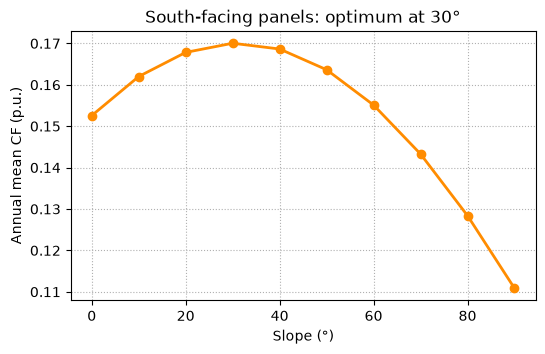

In [6]:
slopes = range(0, 91, 10)
cf_slope = pd.Series({slope: annual_cf(orientation={"slope": float(slope), "azimuth": 180.0}) for slope in slopes})

ax = cf_slope.plot(figsize=(6, 3.5), color="darkorange", lw=2, marker="o", xlabel="Slope (°)", ylabel="Annual mean CF (p.u.)",
                   title=f"South-facing panels: optimum at {cf_slope.idxmax()}°")
ax.grid(ls=":", which="both")

### Tracking

Instead of a fixed orientation, panels can follow the sun: around one axis (`tracking="horizontal"`: a north–south axis, the panel turns from east to west during the day) or around two axes (`tracking="dual"`: the panel always faces the sun). Single-axis trackers are common in the large solar parks of Spain.

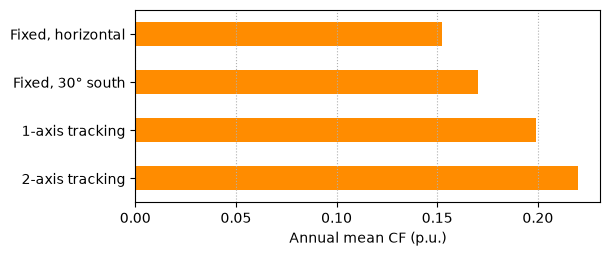

In [7]:
configs = {
    "Fixed, horizontal": dict(orientation={"slope": 0.0, "azimuth": 180.0}),
    "Fixed, 30° south": dict(orientation={"slope": 30.0, "azimuth": 180.0}),
    "1-axis tracking": dict(orientation={"slope": 0.0, "azimuth": 180.0}, tracking="horizontal"),
    "2-axis tracking": dict(orientation={"slope": 0.0, "azimuth": 180.0}, tracking="dual"),
}
cf_configs = pd.Series({name: annual_cf(**kwargs) for name, kwargs in configs.items()})

ax = cf_configs.plot.barh(figsize=(6, 2.5), color="darkorange", xlabel="Annual mean CF (p.u.)")
ax.invert_yaxis()
ax.grid(ls=":", axis="x")

The extra energy of tracking has a cost: more expensive structures and more land per MW. For the rest of the tutorial, fixed crystalline silicon panels facing south with a slope of 30° are used.

In [8]:
panel = "CSi"
orientation = {"slope": 30.0, "azimuth": 180.0}

## 4. Capacity factor of each grid cell

With `aggregate_time="mean"` and no region, `cutout.pv(...)` returns the annual mean capacity factor of every grid cell (a map). As the irradiation (tutorial B1), it increases towards the south.

Where the radiation data are missing (open sea), atlite returns a capacity factor of 0. These cells are masked (`.where(...)`) so that they appear blank.

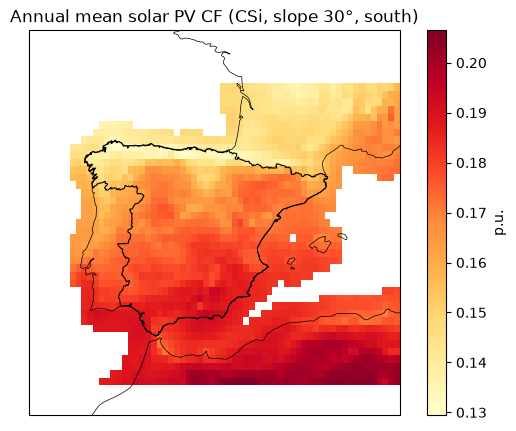

In [9]:
has_data = cutout.data["influx_direct"].notnull().any("time")  # cells with radiation data
cf_map = cutout.pv(panel=panel, orientation=orientation, aggregate_time="mean").where(has_data)

fig, ax = plt.subplots(1, 1, figsize=(7, 5), subplot_kw={"projection": ccrs.PlateCarree()})
cf_map.plot(ax=ax, cmap="YlOrRd", cbar_kwargs={"label": "p.u."})
region.plot(ax=ax, edgecolor="black", color="none", lw=0.8)
ax.coastlines(lw=0.5)
ax.set_title(f"Annual mean solar PV CF ({panel}, slope {orientation['slope']:.0f}°, south)");

Distribution of the capacity factors of the cells of peninsular Spain, weighted by their share inside the region (`weights`): the share of the area of peninsular Spain with each capacity factor. Compare with the distribution of the wind capacity factors in tutorial B2: the solar resource is much more uniform.

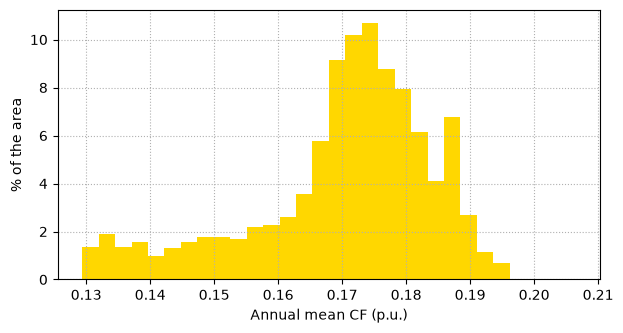

In [10]:
area_share = 100 * weights / weights.sum()  # % of the area of peninsular Spain in each cell

ax = pd.Series(cf_map.values.ravel()).plot.hist(bins=30, weights=area_share.values.ravel(), figsize=(7, 3.5), color=colors["solar"])
ax.set_xlabel("Annual mean CF (p.u.)")
ax.set_ylabel("% of the area")
ax.grid(ls=":", which="both")

## 5. Aggregated profile of peninsular Spain

A power system model with one bus for peninsular Spain needs **one** time series. With `shapes=region`, atlite aggregates the grid cells with the indicator matrix: each cell weighs as much as its area inside the region. This assumes that the panels are spread **uniformly** over the region. With `per_unit=True` the result is a capacity factor (not MW), and with `aggregate_time=None` it keeps the hourly resolution.

In [11]:
cf = cutout.pv(panel=panel, orientation=orientation, shapes=region, per_unit=True, aggregate_time=None).to_pandas()["Peninsular Spain"]
cf.head()

time
2020-01-01 00:00:00    0.0
2020-01-01 01:00:00    0.0
2020-01-01 02:00:00    0.0
2020-01-01 03:00:00    0.0
2020-01-01 04:00:00    0.0
Name: Peninsular Spain, dtype: float64

The annual mean of the aggregated profile equals the area-weighted mean of the cell map of Section 4. Multiplied by the hours of the year, it gives the **full-load hours**: the energy produced per MW installed.

In [12]:
print(f"Annual mean CF (aggregated profile):        {cf.mean():.3f}")
print(f"Area-weighted mean of the cell map:          {float(cf_map.weighted(weights).mean()):.3f}")
print(f"Full-load hours:                             {cf.sum():,.0f} h")

Annual mean CF (aggregated profile):        0.170


Area-weighted mean of the cell map:          0.170
Full-load hours:                             1,494 h


### Hourly time series

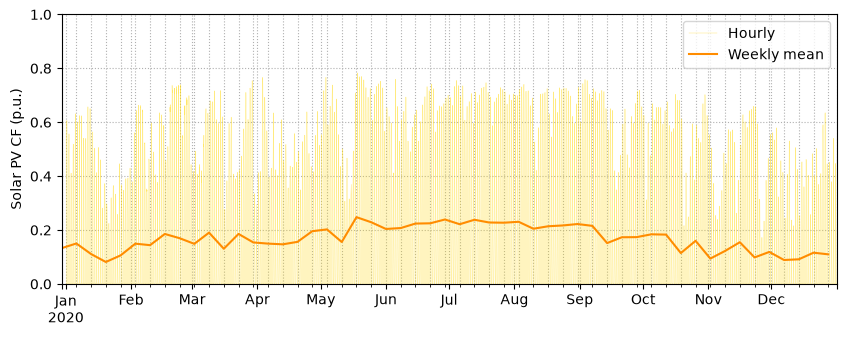

In [13]:
ax = cf.plot(figsize=(10, 3.5), color=colors["solar"], lw=0.3, alpha=0.6, label="Hourly")
cf.resample("W").mean().plot(ax=ax, color="darkorange", lw=1.5, label="Weekly mean")
ax.set_ylim(0, 1)
ax.set_ylabel("Solar PV CF (p.u.)")
ax.set_xlabel("")
ax.grid(ls=":", which="both")
ax.legend(loc="upper right");

Zoom on one summer week (the same as in tutorial B1).

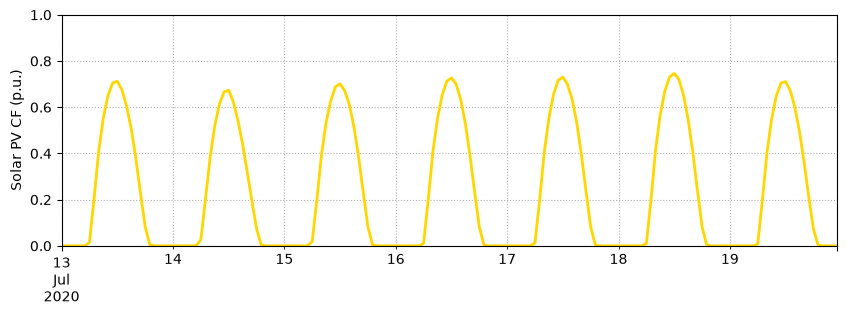

In [14]:
week = slice("2020-07-13", "2020-07-19")  # summer week used in the zoomed plots

ax = cf.loc[week].plot(figsize=(10, 3), color=colors["solar"], lw=2, ylabel="Solar PV CF (p.u.)", xlabel="")
ax.set_ylim(0, 1)
ax.grid(ls=":", which="both")

### Seasonality and duration curve

Monthly mean capacity factor, and the **duration curve**: the hourly values sorted from highest to lowest. Solar PV produces nothing for about half of the hours of the year (the night).

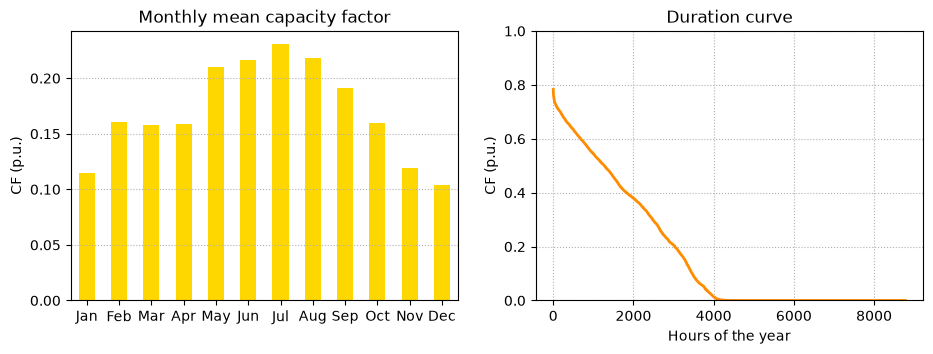

In [15]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.5))

monthly = cf.resample("MS").mean()
monthly.set_axis(monthly.index.strftime("%b")).plot.bar(ax=ax1, color=colors["solar"], rot=0, xlabel="", ylabel="CF (p.u.)",
                                                        title="Monthly mean capacity factor")
ax1.grid(ls=":", axis="y")

pd.Series(cf.sort_values(ascending=False).values).plot(ax=ax2, color="darkorange", lw=2, xlabel="Hours of the year", ylabel="CF (p.u.)",
                                                       title="Duration curve")
ax2.set_ylim(0, 1)
ax2.grid(ls=":", which="both")

## 6. Final remarks

The hourly capacity factor `cf` is the kind of input used as `p_max_pu` of a solar generator in the PyPSA tutorials. Some questions to explore:

- Why is the optimal slope lower than the latitude of Spain (about 40°)? Would it be different if only the winter months mattered?
- How much more could a tracking system cost and still produce energy at the same cost per MWh as fixed panels?
- Compare the monthly capacity factors with those of onshore wind (tutorial B2). In which months is the combination of both technologies most favourable?
- The solar resource is much more uniform over peninsular Spain than the wind resource. What does this mean for the location of solar parks and for the need for transmission lines?